# Middlesex: answers to the cross-county questions

Uses `cases.csv` from `eda_middlesex_2017_2024.ipynb`: duplicates removed, Motor Vehicle Other cases and civil charges dropped.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd

cases =pd.read_csv(Path("../data/middlesex/clean/cases.csv"), index_col="Case Number")

SURFACE, INK, INK_2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]
BLUE = SERIES[0]
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": AXIS,
    "axes.labelcolor": INK_2, "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left", "figure.dpi": 110,
})


def share_bars(shares, title, colors=BLUE):
    """Horizontal bars of shares, in the given order, with % labels."""
    fig, ax = plt.subplots(figsize=(8, 0.4 * len(shares) + 0.8))
    ax.barh(shares.index, shares, color=colors, height=0.65)
    for y, v in enumerate(shares):
        ax.text(v, y, f" {v:.1%}", va="center", fontsize=8, color=INK_2)
    ax.invert_yaxis()
    ax.grid(axis="y", visible=False)
    ax.grid(axis="x", visible=True)
    ax.xaxis.set_major_formatter(mticker.PercentFormatter(1.0))
    ax.margins(x=0.1)
    ax.set_title(title)


def stacked_by_year(shares, colors, title):
    """One horizontal 100% bar per year, one colored segment per column of `shares`."""
    fig, ax = plt.subplots(figsize=(10, 0.45 * len(shares) + 1))
    left = np.zeros(len(shares))
    for col in shares.columns:
        values = shares[col].to_numpy()
        ax.barh(shares.index, values, left=left, color=colors[col], height=0.7,
                edgecolor=SURFACE, linewidth=1, label=col)
        for year, l, v in zip(shares.index, left, values):
            if v >= 0.05:
                ax.text(l + v / 2, year, f"{v:.0%}", ha="center", va="center", fontsize=8,
                        color=INK if colors[col] == SERIES[3] else "white")
        left += values
    ax.set_yticks(shares.index)
    ax.invert_yaxis()
    ax.set_xlim(0, 1)
    ax.xaxis.set_major_formatter(mticker.PercentFormatter(1.0))
    ax.grid(False)
    ax.spines["left"].set_visible(False)
    ax.tick_params(axis="y", length=0)
    ax.legend(ncol=len(shares.columns), loc="lower left", bbox_to_anchor=(0, 1.0), fontsize=8,
              handlelength=1, borderaxespad=0.3, frameon=False)
    ax.set_title(title, pad=28)

## Q1. How many cases were filed each year, and how has that changed since 2017?

The data has no filing date, so each case is counted in the year of its Earliest Event Date (its first court event).

In [2]:
per_year = cases.groupby("sheet_year").size()
q1 = pd.DataFrame({
    "cases": per_year,
    "change vs. prior year": per_year.pct_change(),
    "change vs. 2017": per_year / per_year.loc[2017] - 1,
}).rename_axis("year")

q1.style.format({"cases": "{:,}", "change vs. prior year": "{:+.1%}", "change vs. 2017": "{:+.1%}"}, na_rep="")

,cases,change vs. prior year,change vs. 2017
year,,,
2017,"16,749",,+0.0%
2018,"16,042",-4.2%,-4.2%
2019,"15,308",-4.6%,-8.6%
2020,"10,287",-32.8%,-38.6%
2021,"12,359",+20.1%,-26.2%
2022,"12,703",+2.8%,-24.2%
2023,"13,617",+7.2%,-18.7%
2024,"14,536",+6.7%,-13.2%


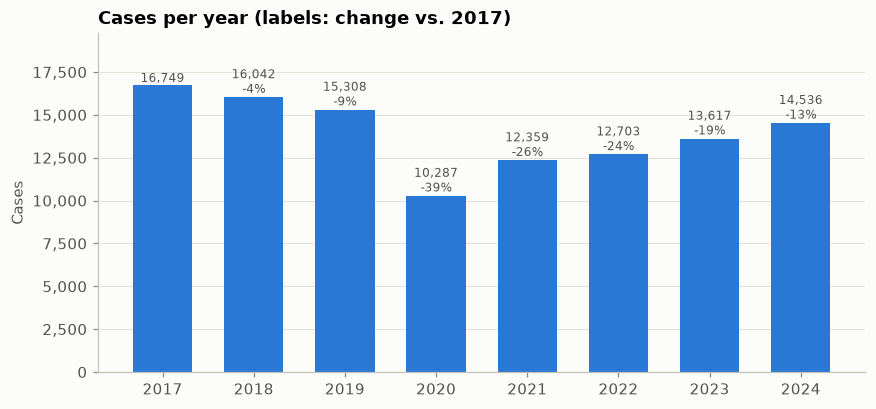

In [3]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(per_year.index, per_year, color=BLUE, width=0.65)
for year, n in per_year.items():
    change = "" if year == 2017 else f"\n{n / per_year.loc[2017] - 1:+.0%}"
    ax.text(year, n, f"{n:,}{change}", ha="center", va="bottom", fontsize=8, color=INK_2)
ax.set_xticks(per_year.index)
ax.yaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))
ax.set_ylim(0, per_year.max() * 1.18)
ax.set_ylabel("Cases")
ax.set_title("Cases per year (labels: change vs. 2017)");

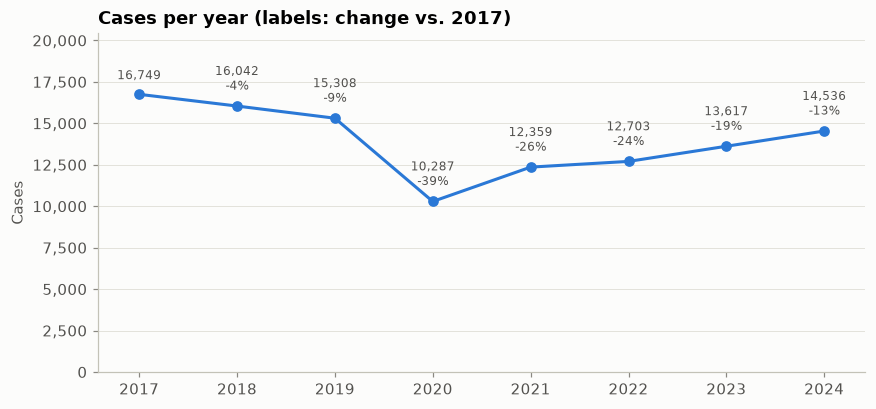

In [4]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(per_year.index, per_year, color=BLUE, lw=2, marker="o", markersize=6)
for year, n in per_year.items():
    change = "" if year == 2017 else f"\n{n / per_year.loc[2017] - 1:+.0%}"
    ax.annotate(f"{n:,}{change}", (year, n), xytext=(0, 8), textcoords="offset points",
                ha="center", va="bottom", fontsize=8, color=INK_2)
ax.set_xticks(per_year.index)
ax.yaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))
ax.set_ylim(0, per_year.max() * 1.22)
ax.margins(x=0.06)
ax.set_ylabel("Cases")
ax.set_title("Cases per year (labels: change vs. 2017)");

**Answer:** Middlesex had **14,536 cases in 2024, 13% fewer than in 2017 (16,749)**. Cases were already falling before COVID-19 (−9% by 2019), dropped to 10,287 in 2020, and have grown every year since without returning to 2017 levels.

## Q2. How many cases are filed per 10,000 residents?

**Population:** Census Bureau July 1 estimates for Middlesex County, MA, saved in `population.csv`. 2017–2019 come from the [2010–2020 intercensal estimates](https://www2.census.gov/programs-surveys/popest/datasets/2010-2020/intercensal/county/asrh/), which match the 2020 Census. 2020–2024 come from the [Vintage 2024 estimates](https://www2.census.gov/programs-surveys/popest/datasets/2020-2024/counties/totals/).

In [5]:
population = pd.read_csv(Path("../data/middlesex/population.csv"), index_col="year")
population.style.format({"population": "{:,}"})

,population,source
year,,
2017,"1,620,034",Census 2010-2020 intercensal estimates (cc-est2020int-agesex-25.csv)
2018,"1,625,887",Census 2010-2020 intercensal estimates (cc-est2020int-agesex-25.csv)
2019,"1,630,745",Census 2010-2020 intercensal estimates (cc-est2020int-agesex-25.csv)
2020,"1,627,578",Census Vintage 2024 estimates (co-est2024-alldata.csv)
2021,"1,620,553",Census Vintage 2024 estimates (co-est2024-alldata.csv)
2022,"1,629,805",Census Vintage 2024 estimates (co-est2024-alldata.csv)
2023,"1,644,932",Census Vintage 2024 estimates (co-est2024-alldata.csv)
2024,"1,668,956",Census Vintage 2024 estimates (co-est2024-alldata.csv)


In [6]:
q2 = pd.DataFrame({"cases": per_year, "population": population.population}).rename_axis("year")
q2["per 10,000 residents"] = q2.cases / q2.population * 10_000
q2.style.format({"cases": "{:,}", "population": "{:,}", "per 10,000 residents": "{:.1f}"})

,cases,population,"per 10,000 residents"
year,,,
2017,"16,749","1,620,034",103.4
2018,"16,042","1,625,887",98.7
2019,"15,308","1,630,745",93.9
2020,"10,287","1,627,578",63.2
2021,"12,359","1,620,553",76.3
2022,"12,703","1,629,805",77.9
2023,"13,617","1,644,932",82.8
2024,"14,536","1,668,956",87.1


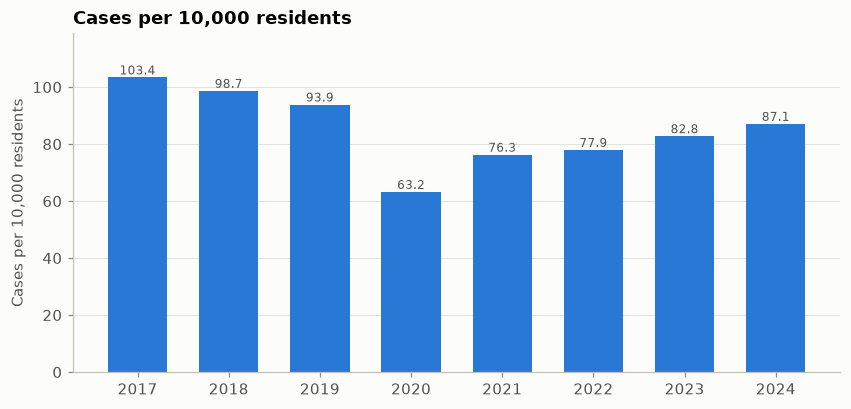

In [7]:
rate = q2["per 10,000 residents"]
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(rate.index, rate, color=BLUE, width=0.65)
for year, r in rate.items():
    ax.text(year, r, f"{r:.1f}", ha="center", va="bottom", fontsize=8, color=INK_2)
ax.set_xticks(rate.index)
ax.set_ylim(0, rate.max() * 1.15)
ax.set_ylabel("Cases per 10,000 residents")
ax.set_title("Cases per 10,000 residents");

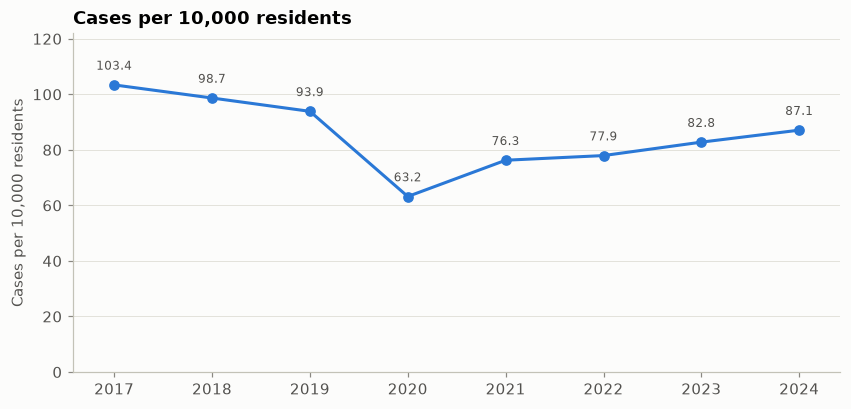

In [8]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(rate.index, rate, color=BLUE, lw=2, marker="o", markersize=6)
for year, r in rate.items():
    ax.annotate(f"{r:.1f}", (year, r), xytext=(0, 8), textcoords="offset points",
                ha="center", va="bottom", fontsize=8, color=INK_2)
ax.set_xticks(rate.index)
ax.set_ylim(0, rate.max() * 1.18)
ax.margins(x=0.06)
ax.set_ylabel("Cases per 10,000 residents")
ax.set_title("Cases per 10,000 residents");

**Answer:** Middlesex had **87 cases per 10,000 residents in 2024**, down from 103 in 2017 (−16%). The rate fell slightly more than the case count (−13%) because the population grew 3%. It was lowest in 2020 (63) and has risen every year since.

## Q3. Of charged cases, what share end in dismissal, diversion, plea, trial conviction, or acquittal?

Each charge's disposition is put into one outcome, and a case takes its most serious one (trial conviction > plea > CWOF > diversion > acquittal > dismissal).

- **Dismissal** includes nolle prosequi and grand jury no-bills.
- **Plea** is a guilty plea. It also includes "guilty filed" and "guilty fines", which don't record whether there was a trial.
- **CWOF** (continued without a finding) is shown on its own: the defendant admits the facts, but there's no conviction if they complete probation.
- **Not resolved / other** is open, defaulted and transferred cases. Shares are of resolved cases.

In [9]:
charges = pd.read_csv(Path("../data/middlesex/clean/charges.csv"), usecols=["Case Number", "Imposed Disposition", "disp_group", "Sentence Type Imposed"])
disposition = charges["Imposed Disposition"].str.upper().fillna("")
group = charges["disp_group"]

RANK = ["Trial conviction", "Plea", "CWOF", "Diversion", "Acquittal", "Dismissal", "Not resolved / other"]
charges["outcome"] = np.select(
    [
        group.eq("Guilty / delinquent") & disposition.str.contains("TRIAL"),
        group.eq("Guilty / delinquent"),
        group.eq("CWOF"),
        group.eq("Pretrial probation / diversion"),
        group.eq("Not guilty") & ~disposition.str.startswith(("NO BILL", "NO PROBABLE CAUSE")),
        group.isin(["Dismissed", "Nolle prosequi", "Not guilty"]),
    ],
    RANK[:-1],
    RANK[-1],
)
case_outcome = charges.outcome.map(RANK.index).groupby(charges["Case Number"]).min().map(dict(enumerate(RANK)))

ORDER = ["Dismissal", "Diversion", "Plea", "CWOF", "Trial conviction", "Acquittal"]
counts = case_outcome.value_counts()
resolved = counts.reindex(ORDER).sum()
print(f"{resolved:,} of {counts.sum():,} cases are resolved")

q3 = pd.DataFrame({"cases": counts.reindex(ORDER + ["Not resolved / other"])})
q3["% of resolved cases"] = (q3.cases / resolved).where(q3.index != "Not resolved / other")
q3.style.format({"cases": "{:,}", "% of resolved cases": "{:.1%}"}, na_rep="")

101,307 of 111,601 cases are resolved


,cases,% of resolved cases
outcome,,
Dismissal,"56,400",55.7%
Diversion,"8,035",7.9%
Plea,"16,654",16.4%
CWOF,"14,724",14.5%
Trial conviction,"1,914",1.9%
Acquittal,"3,580",3.5%
Not resolved / other,"10,294",


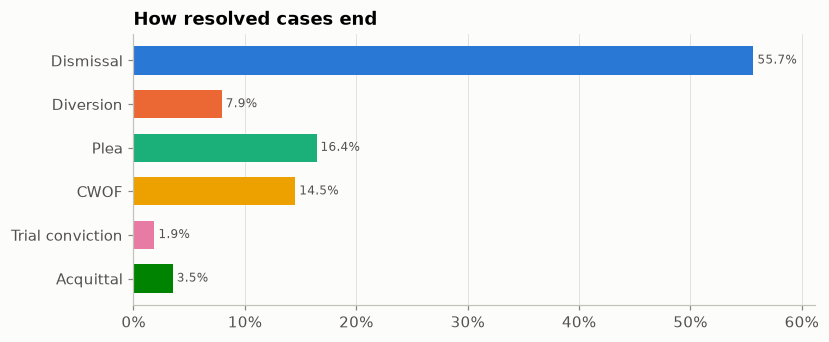

In [10]:
OUTCOME_COLORS = dict(zip(ORDER, SERIES))
share_bars(q3["% of resolved cases"].dropna(), "How resolved cases end", colors=[OUTCOME_COLORS[o] for o in ORDER])

**By year.** The same shares for each year's resolved cases. Recent years have more unresolved cases, so their mix leans toward outcomes that happen quickly.

In [11]:
by_year = pd.crosstab(cases.sheet_year, case_outcome).rename_axis(index="year", columns=None)
q3_year = by_year[ORDER].div(by_year[ORDER].sum(axis=1), axis=0)
q3_year["% not resolved"] = by_year["Not resolved / other"] / by_year.sum(axis=1)
q3_year.style.format("{:.1%}")

,Dismissal,Diversion,Plea,CWOF,Trial conviction,Acquittal,% not resolved
year,,,,,,,
2017,49.8%,8.0%,19.5%,16.7%,2.4%,3.5%,3.4%
2018,51.9%,7.4%,19.1%,15.1%,2.6%,3.9%,3.5%
2019,52.3%,8.8%,18.1%,14.8%,2.2%,3.9%,4.0%
2020,59.0%,8.6%,14.9%,12.6%,1.5%,3.5%,4.4%
2021,58.5%,8.2%,14.8%,13.1%,1.6%,3.8%,5.0%
2022,59.2%,8.5%,13.6%,13.3%,1.6%,3.8%,5.9%
2023,58.4%,7.5%,14.3%,14.9%,1.6%,3.3%,9.9%
2024,62.4%,6.1%,14.2%,14.4%,0.7%,2.2%,37.0%


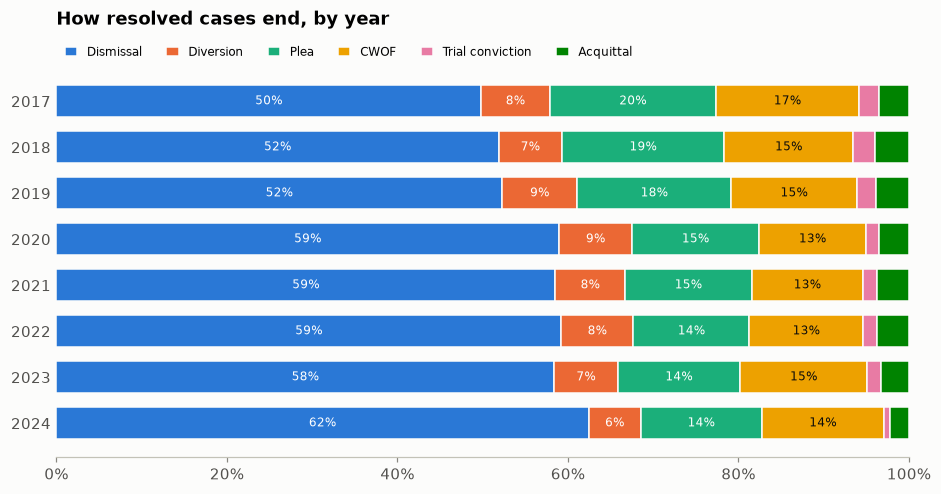

In [12]:
stacked_by_year(q3_year[ORDER], OUTCOME_COLORS, "How resolved cases end, by year")

**Answer:** Of 101,307 resolved cases, **56% were dismissed**, 8% went to diversion, 16% ended in a guilty plea and 15% in a CWOF admission. Only about 5% went to trial, and more of those ended in acquittal (3.5%) than conviction (1.9%).

**By year:** dismissals rose from 50% of resolved cases in 2017 to about 59% from 2020 on, while guilty pleas fell from 20% to about 14% and trial convictions from 2.4% to 1.6%. 2024 (62% dismissed) is incomplete: 37% of its cases aren't resolved yet.

## Q4. What share of convictions result in incarceration, probation, or fines/other?

Convictions are the cases that ended in a plea or trial conviction in Q3 (CWOF isn't a conviction). A case takes the most serious sentence among its guilty charges.

- **Incarceration:** committed (jail, prison or DYS), split sentences (part served, rest suspended) and life sentences.
- **Probation:** probation and suspended sentences.
- **Fines / other:** fines, filed (no sentence imposed) and CWOF on a guilty charge.

In [13]:
convicted = case_outcome[case_outcome.isin(["Trial conviction", "Plea"])].index
guilty = charges[charges["Case Number"].isin(convicted) & charges.disp_group.eq("Guilty / delinquent")]
sentence_type = guilty["Sentence Type Imposed"].fillna("")

SENTENCES = ["Incarceration", "Probation", "Fines / other", "Not recorded"]
guilty_sentence = pd.Series(
    np.select(
        [
            sentence_type.str.contains("Committed|CMTD|Life|Split"),
            sentence_type.str.contains("Probation|Suspended"),
            sentence_type.ne(""),
        ],
        SENTENCES[:-1],
        SENTENCES[-1],
    ),
    index=guilty.index,
)
case_sentence = guilty_sentence.map(SENTENCES.index).groupby(guilty["Case Number"]).min().map(dict(enumerate(SENTENCES)))

counts = case_sentence.value_counts().reindex(SENTENCES, fill_value=0)
recorded = counts.drop("Not recorded").sum()
print(f"{len(convicted):,} convictions, {recorded:,} with a recorded sentence")

q4 = pd.DataFrame({"cases": counts})
q4["% of convictions"] = (q4.cases / recorded).where(q4.index != "Not recorded")
q4.style.format({"cases": "{:,}", "% of convictions": "{:.1%}"}, na_rep="")

18,568 convictions, 17,670 with a recorded sentence


,cases,% of convictions
Incarceration,"6,938",39.3%
Probation,"8,797",49.8%
Fines / other,"1,935",11.0%
Not recorded,898,


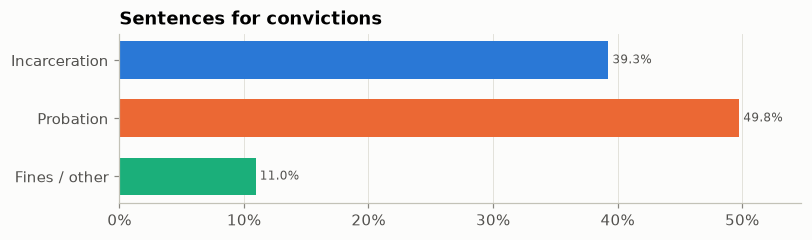

In [14]:
SENTENCE_COLORS = dict(zip(SENTENCES[:-1], SERIES))
share_bars(q4["% of convictions"].dropna(), "Sentences for convictions",
           colors=[SENTENCE_COLORS[s] for s in SENTENCES[:-1]])

**By year.** The same shares for each year's convictions with a recorded sentence.

In [15]:
sentence_by_year = pd.crosstab(cases.sheet_year, case_sentence).rename_axis(index="year", columns=None)
recorded_by_year = sentence_by_year[SENTENCES[:-1]]
q4_year = recorded_by_year.div(recorded_by_year.sum(axis=1), axis=0)
q4_year["convictions"] = sentence_by_year.sum(axis=1)
q4_year["% not recorded"] = sentence_by_year["Not recorded"] / sentence_by_year.sum(axis=1)
q4_year.style.format("{:.1%}").format("{:,}", subset=["convictions"])

,Incarceration,Probation,Fines / other,convictions,% not recorded
year,,,,,
2017,42.0%,53.3%,4.6%,"3,549",12.9%
2018,39.8%,53.3%,6.9%,"3,354",9.7%
2019,37.7%,51.6%,10.7%,"2,982",3.0%
2020,41.6%,46.7%,11.7%,"1,611",1.3%
2021,43.6%,45.1%,11.4%,"1,931",0.0%
2022,37.7%,49.0%,13.3%,"1,822",0.0%
2023,34.1%,49.3%,16.5%,"1,954",0.0%
2024,35.7%,42.2%,22.1%,"1,365",0.3%


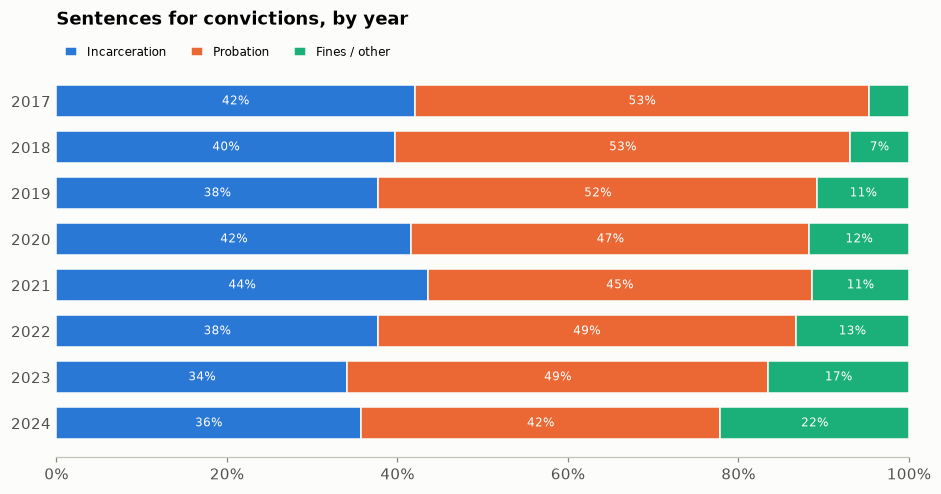

In [16]:
stacked_by_year(q4_year[SENTENCES[:-1]], SENTENCE_COLORS, "Sentences for convictions, by year")

**Answer:** Of 17,670 convictions with a recorded sentence, **39% resulted in incarceration**, 50% in probation (including suspended sentences) and 11% in fines or other outcomes, mostly cases filed without a sentence. 898 convictions (5%) have no sentence recorded.

**By year:** incarceration stayed between 34% and 44%, while fines/other grew from 5% of convictions in 2017 to 22% in 2024 and probation fell from 53% to 42%. Part of the early gap is that 2017 and 2018 have more convictions with no sentence recorded (13% and 10%), and 2024 is still incomplete.

## Q5. What share of defendants are held pretrial, and how often is cash bail set?

**Can't be answered with this data.** The Middlesex extract has no bail amount, bail type (cash or personal recognizance), detention status, or dangerousness-hearing fields.

The closest field, `Jail Credit` (days already served, credited at sentencing), is filled for only 1.3% of charges. It's only recorded for people who were sentenced, so it can't show who was held before trial or whether bail was set.

Answering this would need pretrial records from the courts, probation or the sheriff's office.

## Q6. What is the median time from filing to disposition, and does it differ by case type?

**No filing date, so this measures Earliest Event Date → last disposition, closed cases only.** Cases with bad dates (offense after the earliest event, or no event date) are left out. Case type is the case's crime type; the comparison shows the 10 most common types.

In [17]:
closed = cases.dropna(subset=["days_to_close"])
overall = closed.days_to_close.median()
print(f"{len(closed):,} closed cases, median {overall:.0f} days")

top_types = closed.crime_type.value_counts().head(10).index
q6 = (closed[closed.crime_type.isin(top_types)]
      .groupby("crime_type").days_to_close.agg(cases="size", median_days="median")
      .sort_values("median_days").rename_axis("crime type"))
q6.style.format({"cases": "{:,}", "median_days": "{:.0f}"})

101,098 closed cases, median 172 days


,cases,median_days
crime type,,
Public Order/Other,"7,051",32
Public Policy Other,"2,196",95
Larceny Other,"13,036",136
Physical Assault,"26,009",170
Destruction of Property,"2,748",180
Drugs/Possession,"4,057",186
Violation of Restraining Order,"5,264",191
Physical Assault with a Weapon,"9,020",194
Motor Vehicle OUI,"12,622",197


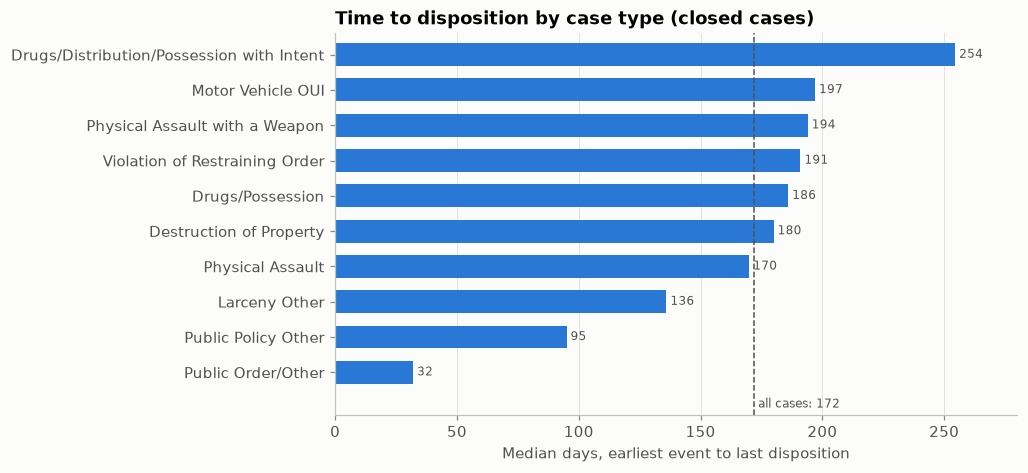

In [18]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(q6.index, q6.median_days, color=BLUE, height=0.65)
for y, v in enumerate(q6.median_days):
    ax.text(v, y, f" {v:.0f}", va="center", fontsize=8, color=INK_2)
ax.axvline(overall, color=INK_2, lw=1, ls="--")
ax.text(overall, -0.9, f" all cases: {overall:.0f}", fontsize=8, color=INK_2, va="center")
ax.set_ylim(-1.2, len(q6) - 0.4)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.margins(x=0.1)
ax.set_xlabel("Median days, earliest event to last disposition")
ax.set_title("Time to disposition by case type (closed cases)");

**By year.** Median days for each year's closed cases. `% not counted` is the share of that year's cases that are still open or otherwise left out.

In [19]:
q6_year = pd.DataFrame({
    "closed cases": closed.groupby("sheet_year").size(),
    "median days": closed.groupby("sheet_year").days_to_close.median(),
    "% not counted": cases.days_to_close.isna().groupby(cases.sheet_year).mean(),
}).rename_axis("year")
q6_year.style.format({"closed cases": "{:,}", "median days": "{:.0f}", "% not counted": "{:.1%}"})

,closed cases,median days,% not counted
year,,,
2017,"16,114",145,3.8%
2018,"15,443",158,3.7%
2019,"14,668",197,4.2%
2020,"9,808",282,4.7%
2021,"11,699",214,5.3%
2022,"11,938",181,6.0%
2023,"12,270",167,9.9%
2024,"9,158",120,37.0%


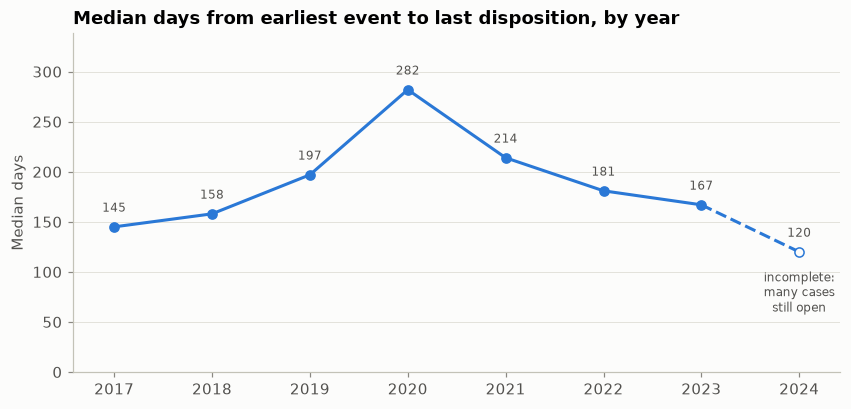

In [20]:
median_days = q6_year["median days"]
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(median_days.loc[:2023].index, median_days.loc[:2023], color=BLUE, lw=2, marker="o", markersize=6)
ax.plot(median_days.loc[2023:].index, median_days.loc[2023:], color=BLUE, lw=2, ls="--")
ax.plot(2024, median_days.loc[2024], marker="o", markersize=6, color=BLUE, markerfacecolor=SURFACE)
for year, d in median_days.items():
    ax.annotate(f"{d:.0f}", (year, d), xytext=(0, 8), textcoords="offset points",
                ha="center", va="bottom", fontsize=8, color=INK_2)
ax.annotate("incomplete:\nmany cases\nstill open", (2024, median_days.loc[2024]), xytext=(0, -12),
            textcoords="offset points", ha="center", va="top", fontsize=8, color=INK_2)
ax.set_xticks(median_days.index)
ax.set_ylim(0, median_days.max() * 1.2)
ax.margins(x=0.06)
ax.set_ylabel("Median days")
ax.set_title("Median days from earliest event to last disposition, by year");

**Answer:** The median closed case took **172 days** (about 6 months) from the first court event to the last disposition. It differs a lot by case type: Public Order/Other cases close fastest (median 32 days) and Larceny Other in 136, while drug distribution cases take the longest (254 days). OUI, assault with a weapon and restraining-order violations take about 190–200 days.

**By year:** the median rose from 145 days for 2017 cases to 282 days for 2020 cases (the COVID-19 backlog), then fell back to 167 days by 2023. 2024's 120 days is low because its slower cases are still open, so they aren't counted yet.

## Q7. Do dismissal and incarceration rates differ by race/ethnicity and sex?

- **Dismissal rate:** share of resolved cases that ended in dismissal (Q3).
- **Incarceration rate:** share of convictions with a recorded sentence that ended in incarceration (Q4).

**Data gaps:**
- Race is unknown for 11% of cases, and sex for 1%.
- Ethnicity is weak. It's "Not Provided" or blank for 37% of cases.
- Hispanic/Latino is recorded under ethnicity, and almost never under race (340 cases). So race and ethnicity are shown separately rather than combined, and the Hispanic/Latino numbers only cover cases where ethnicity was recorded.

These are raw differences, not controlled for offense or prior record (that's Q8).

In [21]:
RACE = {"White": "White", "Black or African American": "Black", "Asian": "Asian",
        "American Indian/Alaska Native": "Other", "Native Hawaiian/Pacific Islander": "Other", "Hispanic/Latino": "Other"}
ETHNICITY = {"Hispanic/Latino": "Hispanic/Latino", "Non-Hispanic/Non-Latino": "Not Hispanic/Latino"}
SEX = {"Male": "Male", "Female": "Female"}
GROUPS = {
    "race": ["White", "Black", "Asian", "Other", "Unknown"],
    "ethnicity": ["Hispanic/Latino", "Not Hispanic/Latino", "Unknown"],
    "sex": ["Male", "Female", "Unknown"],
}

people = pd.DataFrame({
    "race": cases.race.map(RACE).fillna("Unknown"),
    "ethnicity": cases.ethnicity.map(ETHNICITY).fillna("Unknown"),
    "sex": cases.gender.map(SEX).fillna("Unknown"),
    "outcome": case_outcome,
    "sentence": case_sentence,
})
resolved_cases = people[people.outcome.ne("Not resolved / other")]
sentenced = people[people.sentence.notna() & people.sentence.ne("Not recorded")]


def rates(by):
    return pd.DataFrame({
        "resolved cases": resolved_cases.groupby(by).size(),
        "% dismissed": resolved_cases.outcome.eq("Dismissal").groupby(resolved_cases[by]).mean(),
        "convictions": sentenced.groupby(by).size(),
        "% incarcerated": sentenced.sentence.eq("Incarceration").groupby(sentenced[by]).mean(),
    }).reindex(GROUPS[by]).rename_axis(by)


q7 = {by: rates(by) for by in GROUPS}
print(f"All cases: {resolved_cases.outcome.eq('Dismissal').mean():.1%} dismissed, "
      f"{sentenced.sentence.eq('Incarceration').mean():.1%} incarcerated")
FORMAT = {"resolved cases": "{:,}", "convictions": "{:,}", "% dismissed": "{:.1%}", "% incarcerated": "{:.1%}"}
for table in q7.values():
    display(table.style.format(FORMAT))

All cases: 55.7% dismissed, 39.3% incarcerated


,resolved cases,% dismissed,convictions,% incarcerated
race,,,,
White,"67,075",53.9%,"12,332",37.3%
Black,"18,817",58.7%,"3,515",45.9%
Asian,"3,599",58.5%,422,36.3%
Other,457,52.7%,57,49.1%
Unknown,"11,359",60.3%,"1,344",40.3%


,resolved cases,% dismissed,convictions,% incarcerated
ethnicity,,,,
Hispanic/Latino,"18,553",60.9%,"3,042",44.2%
Not Hispanic/Latino,"45,070",54.5%,"9,240",39.5%
Unknown,"37,684",54.4%,"5,388",36.0%


,resolved cases,% dismissed,convictions,% incarcerated
sex,,,,
Male,"76,461",55.0%,"15,084",41.9%
Female,"23,857",57.8%,"2,477",23.9%
Unknown,989,57.1%,109,29.4%


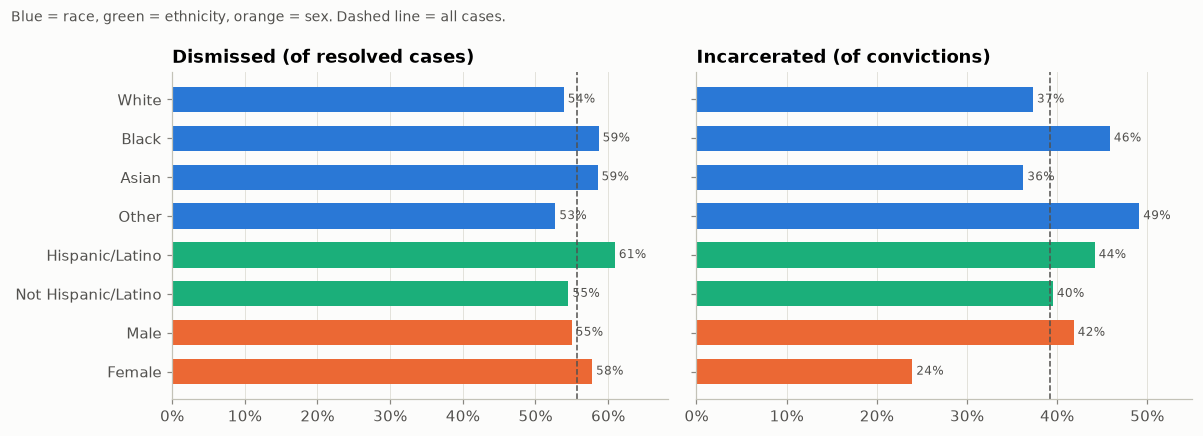

In [22]:
known = pd.concat({by: t.drop(index="Unknown") for by, t in q7.items()})
labels = [group for _, group in known.index]
colors = [{"race": SERIES[0], "ethnicity": SERIES[2], "sex": SERIES[1]}[by] for by, _ in known.index]
overall = {"% dismissed": resolved_cases.outcome.eq("Dismissal").mean(),
           "% incarcerated": sentenced.sentence.eq("Incarceration").mean()}

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, col, title in zip(axes, ["% dismissed", "% incarcerated"],
                          ["Dismissed (of resolved cases)", "Incarcerated (of convictions)"]):
    ax.barh(labels, known[col], color=colors, height=0.65)
    for y, v in enumerate(known[col]):
        ax.text(v, y, f" {v:.0%}", va="center", fontsize=8, color=INK_2)
    ax.axvline(overall[col], color=INK_2, lw=1, ls="--")
    ax.grid(axis="y", visible=False)
    ax.grid(axis="x", visible=True)
    ax.xaxis.set_major_formatter(mticker.PercentFormatter(1.0))
    ax.margins(x=0.12)
    ax.set_title(title)
axes[0].invert_yaxis()
fig.suptitle("Blue = race, green = ethnicity, orange = sex. Dashed line = all cases.", x=0.01, ha="left", fontsize=9, color=INK_2)
fig.tight_layout();

**Answer:** Yes. Dismissal rates differ a little, and incarceration rates differ more.

- **Race:** Black defendants' cases were dismissed slightly more often than White defendants' (59% vs. 54%), but when convicted, Black defendants were incarcerated more often (46% vs. 37%).
- **Ethnicity:** Hispanic/Latino defendants show the same pattern compared with non-Hispanic defendants: 61% vs. 55% dismissed, and 44% vs. 40% incarcerated.
- **Sex:** the biggest gap. Dismissal rates are similar (men 55%, women 58%), but convicted men were incarcerated far more often than convicted women (42% vs. 24%).

The *Other* race group has only 57 convictions, too few to read much into. These are raw gaps; Q8 checks whether they hold within the same offense and prior record.

## Q8. Do racial gaps remain within the same offense category and prior-record level?

**Partly answered: offense category only, not prior record.** This compares incarceration rates (Q4) for White and Black defendants convicted of the same type of offense. Other groups have too few convictions per offense type to compare.

**Why prior record can't be included:**
- The data has no criminal-history field. The only stand-in is earlier Middlesex cases for the same Defendant ID, and that misses a lot:
  - It only reaches back to 2017.
  - It only sees Middlesex cases.
  - It counts earlier cases, not convictions, and can't see the Motor Vehicle Other cases that were filtered out.
- Race is unknown for 11% of cases.
- Splitting further by prior record would leave many groups too small to compare.

So any gap that remains here could still be partly explained by prior record. Answering that would need criminal-history data, such as prior convictions from state court records.

In [23]:
pair = sentenced[sentenced.race.isin(["White", "Black"])].assign(
    crime=cases.crime_type, incarcerated=lambda d: d.sentence.eq("Incarceration")
)
rates = pair.groupby(["crime", "race"]).incarcerated.agg(["mean", "size"]).unstack("race")

# Black incarceration rate if Black defendants had the same mix of offenses as White defendants
white_mix = pair[pair.race.eq("White")].crime.value_counts(normalize=True)
black_rates = rates["mean"]["Black"].dropna()
common = white_mix.index.intersection(black_rates.index)
same_mix = (black_rates[common] * white_mix[common]).sum() / white_mix[common].sum()
raw = pair.groupby("race").incarcerated.mean()
print(f"Incarcerated, raw: White {raw['White']:.1%}, Black {raw['Black']:.1%}")
print(f"Black, at the White offense mix: {same_mix:.1%}")

top = pair.crime.value_counts().head(8).index
q8 = pd.DataFrame({
    "White convictions": rates["size"]["White"],
    "Black convictions": rates["size"]["Black"],
    "White % incarcerated": rates["mean"]["White"],
    "Black % incarcerated": rates["mean"]["Black"],
}).loc[top].rename_axis("crime type")
q8["gap (points)"] = ((q8["Black % incarcerated"] - q8["White % incarcerated"]) * 100).round() + 0  # + 0 turns -0 into 0
q8 = q8.sort_values("gap (points)", ascending=False)
q8.style.format({"White convictions": "{:,.0f}", "Black convictions": "{:,.0f}", "White % incarcerated": "{:.0%}",
                 "Black % incarcerated": "{:.0%}", "gap (points)": "{:+.0f}"})

Incarcerated, raw: White 37.3%, Black 45.9%
Black, at the White offense mix: 41.2%


,White convictions,Black convictions,White % incarcerated,Black % incarcerated,gap (points)
crime type,,,,,
Violation of Restraining Order,867,152,35%,52%,+17
Physical Assault,"1,798",578,38%,48%,+10
Drugs/Possession,676,125,31%,40%,+9
Physical Assault with a Weapon,890,331,52%,57%,+6
Breaking and Entering/Building,483,139,49%,55%,+6
Larceny Other,"1,881",696,36%,37%,+1
Public Order/Other,446,165,33%,33%,+0
Motor Vehicle OUI,"2,095",246,14%,12%,-2


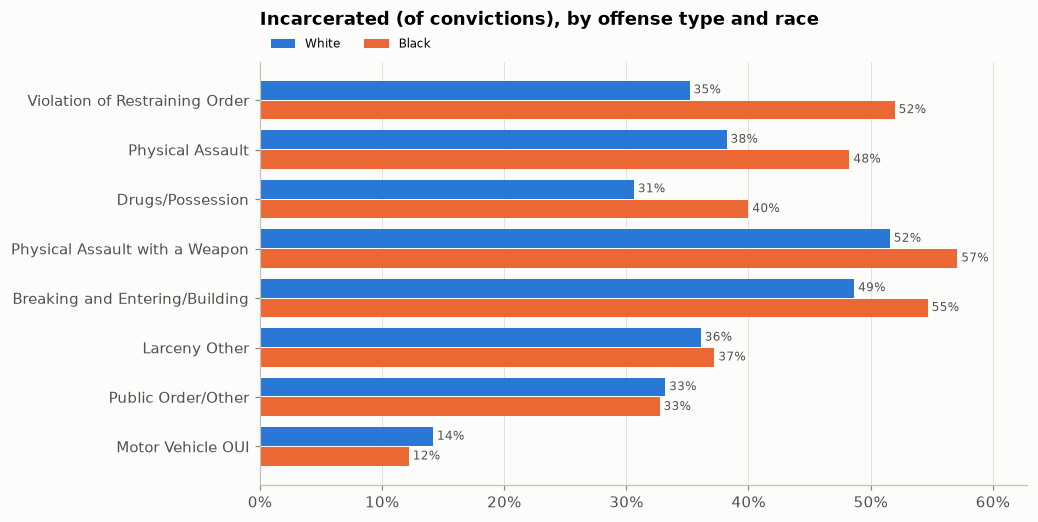

In [24]:
fig, ax = plt.subplots(figsize=(9, 5))
y = np.arange(len(q8))
for offset, race, color in [(-0.2, "White", SERIES[0]), (0.2, "Black", SERIES[1])]:
    values = q8[f"{race} % incarcerated"]
    ax.barh(y + offset, values, height=0.38, color=color, label=race)
    for yi, v in zip(y + offset, values):
        ax.text(v, yi, f" {v:.0%}", va="center", fontsize=8, color=INK_2)
ax.set_yticks(y, q8.index)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.xaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.margins(x=0.1)
ax.legend(ncol=2, loc="lower left", bbox_to_anchor=(0, 1.0), fontsize=8, frameon=False)
ax.set_title("Incarcerated (of convictions), by offense type and race", pad=24);

**Answer:** Partly. Convicted Black defendants were incarcerated more often than White defendants (46% vs. 37%). About half of that gap comes from differences in offense type: with the same mix of offenses as White defendants, the Black rate would be 41%. The other half remains, and it's concentrated in a few offenses: restraining-order violations (52% vs. 35%), physical assault (48% vs. 38%) and drug possession (40% vs. 31%). For larceny, public order and OUI there's no gap.

Prior record isn't controlled for, so part of the remaining gap may reflect differences in criminal history.